## Egyptian pharmaceutical drugs EDA

In [24]:
#import libraries
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:
#read data
eg = pd.read_csv("https://raw.githubusercontent.com/mahmoudfalous/eg-drugs/main/data/eg_drugs.csv")

In [26]:
#show
eg.head()

,id,name,arabic,active,company,price,oldprice,barcode,barcode_valid,slug,units,description,uses
0,1,1 2 3 (one two three) syrup 120 ml,ون تو ثري شراب 120 مل,chlorpheniramine+paracetamol+pseudoephedrine,hikma pharma,40.0,32.0,6.221000e+12,1,1-2-3--one-two-three--syrup-120-ml,1,cold products,تخفيف أعراض نزلات البرد والإنفلونزا مثل الصداع...
1,2,1 2 3 (one two three) 20 f.c.tabs,ون تو ثري 20 قرص,chlorpheniramine+paracetamol+pseudoephedrine,hikma pharma,40.0,24.0,6.221000e+12,1,1-2-3--one-two-three--20-f.c.tabs,2,cold products,تخفيف أعراض نزلات البرد والإنفلونزا مثل الصداع...
2,3,5-fluorouracil-ebewe 250mg/5ml i.v. vial,فلورويوراسيل 250مجم/5مل فيال وريد,fluorouracil,shanghai xudong haipu pharmaceutical > acdima ...,74.0,50.0,9.088881e+12,1,5-fluorouracil-ebewe-250mg-5ml-i.v.-vial,1,antineoplastic,يُستخدم في علاج بعض أنواع سرطان القولون والمست...
3,4,mooagar sachets,مو اجار 2جم اكياس,agar,hexa pharma company,75.0,NaN,NaN,0,mooagar-sachets,1,jaundice,الصفراء عند حديثي الولادة يُستخدم كمُليّن طبيع...
4,5,limitless lactoferrin 100 mg 30 sachets,ليمتلس لاكتوفيرين 100 مجم 30 كيس,lactoferrin,eva pharma,485.0,385.0,NaN,0,limitless-lactoferrin-100-mg-30-sachets,1,iron supplement,يساعد في علاج الأنيميا الناتجة عن نقص الحديد ل...


In [27]:
#data information
eg.info()

<class 'pandas.DataFrame'>
RangeIndex: 27617 entries, 0 to 27616
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             27617 non-null  int64  
 1   name           27617 non-null  str    
 2   arabic         27612 non-null  str    
 3   active         24689 non-null  str    
 4   company        27092 non-null  str    
 5   price          27616 non-null  float64
 6   oldprice       11661 non-null  float64
 7   barcode        10900 non-null  float64
 8   barcode_valid  27617 non-null  int64  
 9   slug           27611 non-null  str    
 10  units          27617 non-null  int64  
 11  description    26286 non-null  str    
 12  uses           8237 non-null   str    
dtypes: float64(3), int64(3), str(7)
memory usage: 2.7 MB


In [28]:
#count null
eg.isnull().sum()

id                   0
name                 0
arabic               5
active            2928
company            525
price                1
oldprice         15956
barcode          16717
barcode_valid        0
slug                 6
units                0
description       1331
uses             19380
dtype: int64

In [29]:
#drop unimportant coulmns
eg = eg.drop(columns=["id", "oldprice", "barcode", "company" ,"uses" , "units", "slug","description","arabic","barcode_valid"])

In [30]:
#numeric columns describe
eg.describe()

,price
count,2.761600e+04
mean,1.909053e+03
std,2.047182e+05
min,0.000000e+00
25%,3.400000e+01
50%,8.400000e+01
75%,1.950000e+02
max,3.400000e+07


In [31]:
#find if any negative or zero values in price col
(eg['price']<=0) .sum()

np.int64(128)

In [32]:
#remove rows with zero or negative price
eg = eg[eg['price'] > 0]

In [33]:
#drop nulls in active column 
eg = eg.dropna()

In [34]:
#clean text
eg["active"] = eg["active"].astype(str).str.lower().str.strip()
eg['name'] = eg['name'].astype(str).str.lower().str.strip()

In [35]:
#drop duplicate drugs and keep the first one
eg = eg.drop_duplicates(subset='name', keep='first')

In [36]:
#calculate outliers for price col

Q1 = eg["price"].quantile(0.25)
Q3 = eg["price"].quantile(0.75)
IQR = Q3 - Q1
    
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
    
outliers_count = len(eg[(eg["price"] < lower_bound) | (eg["price"] > upper_bound)])
    
print(f"{"price"}: {outliers_count} Outliers")

price: 2314 Outliers


In [37]:
#final data info
eg.info()

<class 'pandas.DataFrame'>
Index: 24558 entries, 0 to 27616
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   name    24558 non-null  str    
 1   active  24558 non-null  str    
 2   price   24558 non-null  float64
dtypes: float64(1), str(2)
memory usage: 767.4 KB


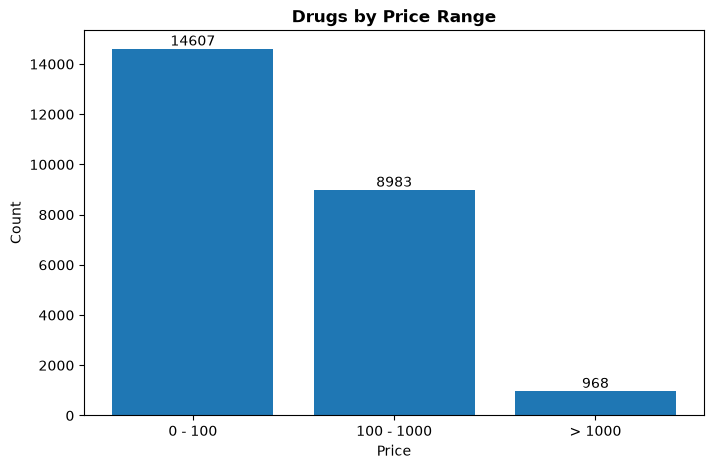

In [38]:
#visualization
price_cat = pd.cut(eg['price'], bins=[0, 100, 1000, float('inf')],
labels=['0 - 100', '100 - 1000', '> 1000'], include_lowest=True)
price_counts = price_cat.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(price_counts.index.astype(str), price_counts.values)
ax.bar_label(bars)
ax.set_title('Drugs by Price Range', fontsize=12, fontweight='bold')
ax.set_xlabel('Price')
ax.set_ylabel('Count')
plt.show()

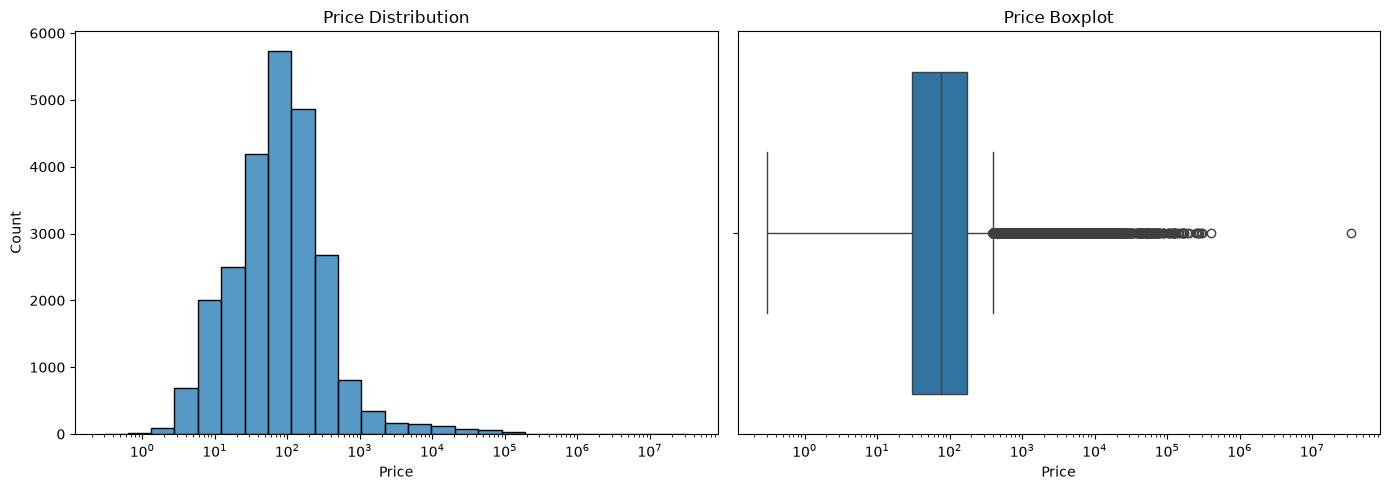

In [39]:
#price distribution using log scale because of heavy skew
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(eg['price'], bins=25, log_scale=True, ax=axes[0])
axes[0].set_title('Price Distribution')
axes[0].set_xlabel('Price')

sns.boxplot(x=eg['price'], ax=axes[1])
axes[1].set_xscale('log')
axes[1].set_title('Price Boxplot')
axes[1].set_xlabel('Price')

plt.tight_layout()
plt.show()

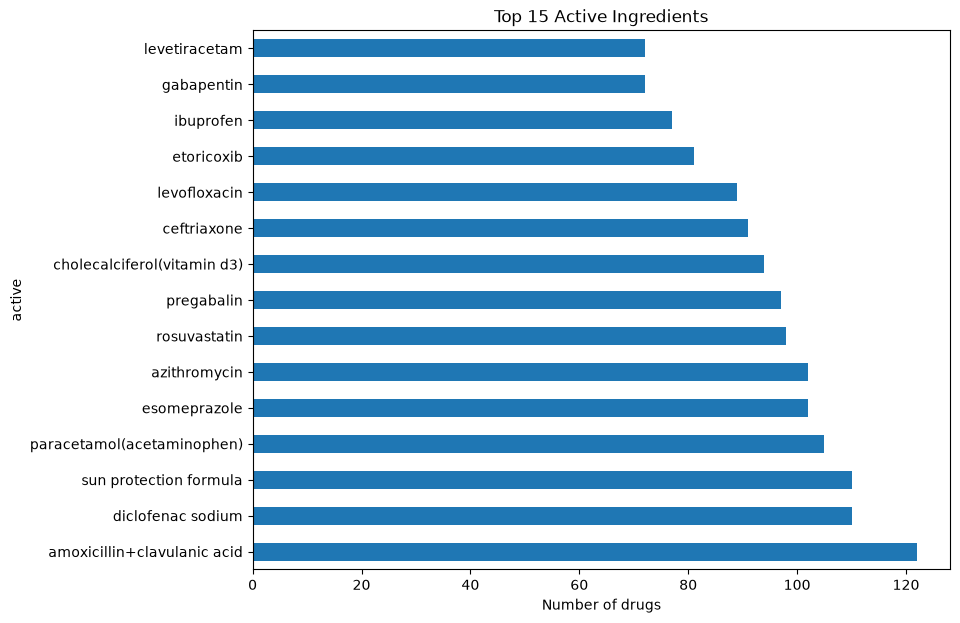

In [40]:
#top 15 active ingredients
active_counts = eg['active'].value_counts().head(15)

active_counts.plot(kind='barh', figsize=(9, 7))
plt.title('Top 15 Active Ingredients')
plt.xlabel('Number of drugs')
plt.show()

In [41]:
#save cleaned data
eg.to_csv("../data/eg_drugs.csv", index=False)

## Key Findings

- **Data size:** 27,617 raw records reduced to **24,558 unique drugs** after cleaning (removed rows with zero/missing price and active and duplicate names).
- **Columns kept:** `name`, `active`, `price` — three essential columns for the drug interaction checker and recommendation system. All other columns (description, arabic, company, etc.) were dropped as they are not needed for the current project scope.
- **Missing values:** after cleaning, zero missing values across all three columns.
- **Price:** median price is **84 EGP** while the mean is about **1,909 EGP**, so the distribution is heavily right-skewed. 25% of drugs cost 34 EGP or less, and 75% cost 195 EGP or less. The highest price (34 million EGP) is a real gene therapy drug, so extreme prices were intentionally kept.
- **Price categories:** the majority of drugs fall in the **0–100 EGP** range, with a small tail in the **>1000 EGP** category.